In [ ]:
!pip install -q torch datasets numpy matplotlib scikit-learn

In [2]:
import time
import warnings
from collections.abc import Callable, Iterator

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
DATASET_NAME = "uoft-cs/cifar100"
EMBED_DIM = 128
# PK sampling: P classes x K images per class in every batch
P_CLASSES, K_IMAGES = 32, 8
EPOCHS = 5
SEED = 0
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# 1) Metric Learning

- A classifier learns a fixed set of decision boundaries; a **metric learner** learns an embedding $f_\theta: \mathcal{X} \to \mathbb{S}^{D-1}$ in which distance means similarity, so it can compare items from classes it has never seen.

- Face verification, person re-identification, product search, image deduplication and every dense retriever are built this way: enrol a gallery once, then answer queries by nearest neighbour.

The open question is which training signal shapes the space best:

| Family | Signal per step | Weak point |
|---|---|---|
| Contrastive (pairs) | pull positive pairs together, push negatives beyond a margin $m$ | most negative pairs are already far: zero gradient |
| Triplet | positive closer than negative by $\alpha$ | needs **mining**: random triplets are mostly easy |
| Proxy / angular-margin softmax (ArcFace, CosFace) | classify against learned class proxies with an angular margin | needs class labels; proxies are discarded at test time |
| Multi-positive InfoNCE (SupCon) | softmax over the whole batch | needs large batches |

All three of the first rows are trained here on the same encoder and evaluated the standard way:
**Recall@K on classes held out from training**.

# 2) Data: Zero-Shot Retrieval on CIFAR-100

- CIFAR-100 has 100 classes of 32 × 32 images.
- The first 50 classes (25,000 training images) are used for training; the other 50 classes (5,000 test images) never appear in training and form the retrieval benchmark.
- Every test image is a query against all the others, and Recall@K is the fraction of queries whose $K$ nearest neighbours contain at least one image of the same class.
- This is the protocol of CUB-200, Cars-196 and Stanford Online Products, at a size that trains in a minute.

In [3]:
# Dataset normalization stats and load CIFAR
MEAN, STD = (0.507, 0.487, 0.441), (0.267, 0.256, 0.276)
cifar = load_dataset(DATASET_NAME)
class_names = cifar["train"].features["fine_label"].names


def load_split(split: str, classes: range) -> tuple[torch.Tensor, torch.Tensor]:
    """Normalised images (N, 3, 32, 32) and labels (N,) of one split and class range."""
    labels = torch.tensor(cifar[split]["fine_label"])
    keep = torch.where((labels >= classes.start) & (labels < classes.stop))[0]
    rows = cifar[split].select(keep.tolist())
    images = torch.from_numpy(np.stack([np.array(im) for im in rows["img"]]))
    images = images.permute(0, 3, 1, 2).contiguous().float() / 255
    mean, std = torch.tensor(MEAN).view(1, 3, 1, 1), torch.tensor(STD).view(1, 3, 1, 1)
    return (images - mean) / std, labels[keep] - classes.start


# Prepare train and test splits with disjoint class ranges
train_x, train_y = load_split("train", range(0, 50))
test_x, test_y = load_split("test", range(50, 100))
print(f"train: {tuple(train_x.shape)}, {train_y.unique().numel()} classes (seen)")
print(
    f"test:  {tuple(test_x.shape)}, {test_y.unique().numel()} classes (unseen), e.g. "
    f"{class_names[50:55]}"
)

train: (25000, 3, 32, 32), 50 classes (seen)
test:  (5000, 3, 32, 32), 50 classes (unseen), e.g. ['mouse', 'mushroom', 'oak_tree', 'orange', 'orchid']


# 3) Encoder, Sampler and Recall@K

The encoder is a small VGG-style CNN (about 1.2 M parameters) ending in global average pooling,
a linear projection to $D = 128$ and L2 normalisation. The same architecture and the same
PK batches (32 classes × 8 images) are used for every loss, so the only difference is the
training signal.

In [4]:
def pairwise_dist(z: torch.Tensor) -> torch.Tensor:
    """(batch_num, D) unit vectors -> (batch_num, batch_num) Euclidean distances."""
    # eps inside the sqrt keeps a gradient at d = 0 (clamp would zero it and let a
    # collapsed embedding stay collapsed)
    return ((2 - 2 * z @ z.T).clamp(min=0) + 1e-6).sqrt()


def contrastive_loss(
    z: torch.Tensor, labels: torch.Tensor, margin: float = 1.0
) -> torch.Tensor:
    """All-pairs contrastive loss over a batch."""
    d = pairwise_dist(z)
    same = labels[:, None] == labels[None, :]
    off_diag = ~torch.eye(len(z), dtype=torch.bool, device=z.device)
    pos = d[same & off_diag].pow(2).mean()
    neg = F.relu(margin - d[~same]).pow(2).mean()
    return pos + neg


def batch_hard_triplet_loss(
    z: torch.Tensor, labels: torch.Tensor, margin: float = 0.3
) -> torch.Tensor:
    """Triplet loss on the hardest positive and hardest negative of each anchor."""
    d = pairwise_dist(z)
    same = labels[:, None] == labels[None, :]
    hardest_pos = d.masked_fill(~same, 0).max(dim=1).values
    hardest_neg = d.masked_fill(same, float("inf")).min(dim=1).values
    return F.relu(hardest_pos - hardest_neg + margin).mean()


def batch_all_triplet_loss(
    z: torch.Tensor, labels: torch.Tensor, margin: float = 0.3
) -> torch.Tensor:
    """Hinge averaged over all valid (anchor, positive, negative) triplets that violate
    it.
    """
    d = pairwise_dist(z)
    same = labels[:, None] == labels[None, :]
    eye = torch.eye(len(z), dtype=torch.bool, device=z.device)
    # (batch_num, batch_num, batch_num) cube indexed [anchor, positive, negative]
    valid = (same & ~eye)[:, :, None] & (~same)[:, None, :]
    hinge = F.relu(d[:, :, None] - d[:, None, :] + margin) * valid
    return hinge.sum() / (hinge > 0).sum().clamp(min=1)


class ArcFaceHead(nn.Module):
    """Class proxies with an additive angular margin on the target logit."""

    def __init__(
        self, embed_dim: int, num_classes: int, s: float = 16.0, m: float = 0.3
    ) -> None:
        super().__init__()
        self.proxies = nn.Parameter(torch.randn(num_classes, embed_dim))
        self.s, self.m = s, m

    def forward(self, z: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        """z (batch_num, D) unit vectors -> scalar loss."""
        cos = z @ F.normalize(self.proxies, dim=1).T
        theta = cos.clamp(-1 + 1e-6, 1 - 1e-6).acos()
        target = F.one_hot(labels, cos.shape[1]).bool()
        logits = torch.where(target, (theta + self.m).cos(), cos)
        return F.cross_entropy(self.s * logits, labels)

In [5]:
# Toy embeddings and labels for quick correctness checks
z_toy = F.normalize(torch.randn(8, 4), dim=1)
y_toy = torch.tensor([0, 0, 1, 1, 2, 2, 3, 3])

# batch-hard triplet == nn.TripletMarginLoss on the explicitly mined triplets
d = pairwise_dist(z_toy)
same = y_toy[:, None] == y_toy[None, :]
pos_idx = d.masked_fill(~same, 0).argmax(1)
neg_idx = d.masked_fill(same, float("inf")).argmin(1)
ref = nn.TripletMarginLoss(margin=0.3, eps=0)(z_toy, z_toy[pos_idx], z_toy[neg_idx])
print(
    f"batch-hard triplet {batch_hard_triplet_loss(z_toy, y_toy):.5f} | "
    f"TripletMarginLoss {ref:.5f}"
)

# ArcFace with m = 0 is softmax cross-entropy on scaled cosines
head = ArcFaceHead(4, 4, m=0.0)
cos = z_toy @ F.normalize(head.proxies, dim=1).T
print(
    f"ArcFace(m=0) {head(z_toy, y_toy):.5f} | CE on s*cos "
    f"{F.cross_entropy(16 * cos, y_toy):.5f}"
)
head.m = 0.3
print(f"ArcFace(m=0.3) {head(z_toy, y_toy):.5f}  (the margin raises the loss)")
print(f"contrastive {contrastive_loss(z_toy, y_toy):.5f}")

# batch-all == mean of the explicit loop over violating triplets
terms = [
    F.relu(d[a, p] - d[a, n] + 0.3)
    for a in range(8)
    for p in range(8)
    for n in range(8)
    if a != p and y_toy[a] == y_toy[p] and y_toy[a] != y_toy[n]
]
loop = torch.stack(terms)
print(
    f"batch-all {batch_all_triplet_loss(z_toy, y_toy):.5f} | loop "
    f"{loop[loop > 0].mean():.5f}"
)

batch-hard triplet 1.02659 | TripletMarginLoss 1.02659
ArcFace(m=0) 7.27618 | CE on s*cos 7.27618
ArcFace(m=0.3) 9.88844  (the margin raises the loss)
contrastive 2.15530
batch-all 0.60207 | loop 0.60207


In [6]:
def make_encoder() -> nn.Module:
    """(batch_num, 3, 32, 32) -> (batch_num, EMBED_DIM) unit vectors."""

    def block(c_in: int, c_out: int) -> list[nn.Module]:
        """Conv-BN-ReLU twice, then 2x2 max-pool."""
        return [
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        ]

    class Normalize(nn.Module):
        """L2-normalise the last dimension."""

        def forward(self, x: torch.Tensor) -> torch.Tensor:
            """Unit vectors along the last dim."""
            return F.normalize(x, dim=-1)

    return nn.Sequential(
        *block(3, 64),
        *block(64, 128),
        *block(128, 192),
        nn.AdaptiveAvgPool2d(1),
        nn.Flatten(),
        nn.Linear(192, EMBED_DIM),
        Normalize(),
    )


def pk_batches(labels: torch.Tensor, p: int, k: int) -> Iterator[torch.Tensor]:
    """One epoch of index batches with p classes x k images each."""
    by_class = [torch.where(labels == c)[0] for c in labels.unique()]
    num_batches = len(labels) // (p * k)
    for _ in range(num_batches):
        classes = torch.randperm(len(by_class))[:p]
        yield torch.cat(
            [by_class[c][torch.randperm(len(by_class[c]))[:k]] for c in classes]
        )


@torch.no_grad()
def embed(model: nn.Module, x: torch.Tensor) -> torch.Tensor:
    """Embed a tensor of images in chunks -> (N, EMBED_DIM) on CPU."""
    model.eval()
    return torch.cat(
        [model(x[s : s + 1000].to(DEVICE)).cpu() for s in range(0, len(x), 1000)]
    )


def recall_at_k(
    z: torch.Tensor, labels: torch.Tensor, ks: tuple[int, ...] = (1, 4, 16)
) -> dict:
    """Every item queries all others; share of queries with a same-class item in the
    top k.
    """
    sim = z @ z.T
    sim.fill_diagonal_(-float("inf"))
    top = sim.topk(max(ks), dim=1).indices
    hit = labels[top] == labels[:, None]
    return {k: hit[:, :k].any(dim=1).float().mean().item() for k in ks}


# Show an example PK batch and create the encoder
print("PK batch:", train_y[next(pk_batches(train_y, 4, 3))].tolist())
encoder = make_encoder()
print(f"encoder params: {sum(p.numel() for p in encoder.parameters()) / 1e6:.2f} M")
print(
    "untrained encoder:",
    {
        k: round(v, 3)
        for k, v in recall_at_k(embed(encoder.to(DEVICE), test_x), test_y).items()
    },
)

PK batch: [32, 32, 32, 48, 48, 48, 18, 18, 18, 13, 13, 13]
encoder params: 0.84 M


untrained encoder: {1: 0.143, 4: 0.331, 16: 0.606}


# 4) End-to-End: Three Losses, Same Encoder

Five epochs each with AdamW and random horizontal flips. Recall@K is measured on the 50 unseen
classes after every epoch; the untrained encoder above is the floor (random features of a CNN
already cluster colour and texture a little).

In [7]:
LossFn = Callable[[torch.Tensor, torch.Tensor], torch.Tensor]


def train(
    loss_fn: LossFn, extra: nn.Module | None = None
) -> tuple[nn.Module, list[float]]:
    """Train a fresh encoder with loss_fn(z, labels); returns it and R@1 per epoch."""
    torch.manual_seed(SEED)
    model = make_encoder().to(DEVICE)
    params = list(model.parameters()) + (list(extra.parameters()) if extra else [])
    opt = torch.optim.AdamW(params, lr=2e-3, weight_decay=5e-4)
    r1 = []
    for epoch in range(EPOCHS):
        model.train()
        for idx in pk_batches(train_y, P_CLASSES, K_IMAGES):
            x = train_x[idx]
            flip = torch.rand(len(x)) < 0.5
            x[flip] = x[flip].flip(-1)
            loss = loss_fn(model(x.to(DEVICE)), train_y[idx].to(DEVICE))
            opt.zero_grad()
            loss.backward()
            opt.step()
        r1.append(recall_at_k(embed(model, test_x), test_y)[1])
        print(f"  epoch {epoch + 1}  loss {loss.item():.3f}  unseen R@1 {r1[-1]:.3f}")
    return model, r1


# Define methods mapping and train each method
arcface = ArcFaceHead(EMBED_DIM, 50).to(DEVICE)
methods = {
    "contrastive": (contrastive_loss, None),
    "triplet, batch-all": (batch_all_triplet_loss, None),
    "ArcFace": (arcface, arcface),
}
trained = {}
for name, (loss_fn, extra) in methods.items():
    print(name)
    start = time.time()
    trained[name] = train(loss_fn, extra)
    print(f"  {time.time() - start:.0f} s")

contrastive


  epoch 1  loss 0.472  unseen R@1 0.151


  epoch 2  loss 0.400  unseen R@1 0.150


  epoch 3  loss 0.395  unseen R@1 0.167


  epoch 4  loss 0.359  unseen R@1 0.186


  epoch 5  loss 0.351  unseen R@1 0.183
  145 s
triplet, batch-all


... (6 outputs left out)

  epoch 2  loss 6.935  unseen R@1 0.211


  epoch 3  loss 6.360  unseen R@1 0.245


  epoch 4  loss 5.267  unseen R@1 0.296


  epoch 5  loss 4.962  unseen R@1 0.310
  109 s


loss                      R@1    R@4   R@16


untrained               0.142  0.307  0.590


contrastive             0.183  0.418  0.713


triplet, batch-all      0.219  0.470  0.745


ArcFace                 0.310  0.548  0.804


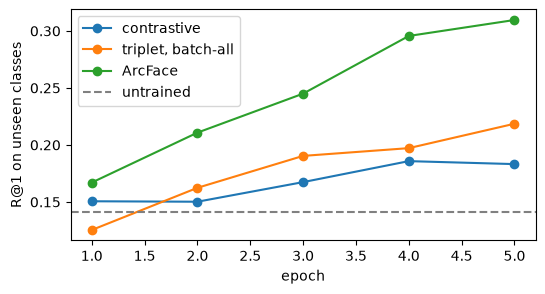

In [8]:
# Evaluate models on unseen classes and plot training R@1
print(f"{'loss':<22} {'R@1':>6} {'R@4':>6} {'R@16':>6}")
baseline = recall_at_k(embed(make_encoder().to(DEVICE), test_x), test_y)
print(f"{'untrained':<22} " + " ".join(f"{v:6.3f}" for v in baseline.values()))
for name, (model, _) in trained.items():
    r = recall_at_k(embed(model, test_x), test_y)
    print(f"{name:<22} " + " ".join(f"{v:6.3f}" for v in r.values()))

plt.figure(figsize=(6, 3))
for name, (_, r1) in trained.items():
    plt.plot(range(1, EPOCHS + 1), r1, marker="o", label=name)
plt.axhline(baseline[1], color="grey", ls="--", label="untrained")
plt.xlabel("epoch")
plt.ylabel("R@1 on unseen classes")
plt.legend()
plt.show()

## 4.1 Which triplets to train on

- Two extremes of mining on the same PK batches: one **random** positive and negative per anchor, and **batch-hard** (the hardest positive and hardest negative per anchor).

- Random triplets are mostly satisfied already and carry little signal.

- Batch-hard from a random initialisation is the classic failure: early on, the hardest pairs are dominated by noise, the gradient pulls every embedding towards the same point, and once all distances are equal the hinge sits at exactly the margin with no useful direction left.

- The mean pairwise distance between test embeddings diagnoses it: it falls to almost zero for a collapsed model.

- Expect batch-hard from scratch to risk collapsing the embedding, while random triplets typically make only slow progress.

In [9]:
def random_triplet_loss(
    z: torch.Tensor, labels: torch.Tensor, margin: float = 0.3
) -> torch.Tensor:
    """Triplet loss with one random positive and one random negative per anchor."""
    d = pairwise_dist(z)
    same = labels[:, None] == labels[None, :]
    off_diag = ~torch.eye(len(z), dtype=torch.bool, device=z.device)
    pos = torch.multinomial((same & off_diag).float(), 1)[:, 0]
    neg = torch.multinomial((~same).float(), 1)[:, 0]
    rows = torch.arange(len(z), device=z.device)
    return F.relu(d[rows, pos] - d[rows, neg] + margin).mean()


# Train models with random and batch-hard triplet losses
for name, loss_fn in [
    ("triplet, random", random_triplet_loss),
    ("triplet, batch-hard", batch_hard_triplet_loss),
]:
    print(name)
    trained[name] = train(loss_fn)

print(f"\n{'loss':<22} {'R@1':>6} {'mean pairwise distance':>24}")
for name, (model, _) in trained.items():
    z = embed(model, test_x[:2000])
    spread = pairwise_dist(z).mean().item()
    print(
        f"{name:<22} {recall_at_k(embed(model, test_x), test_y)[1]:6.3f} {spread:24.3f}"
    )

triplet, random


  epoch 1  loss 0.251  unseen R@1 0.118


  epoch 2  loss 0.221  unseen R@1 0.115


  epoch 3  loss 0.218  unseen R@1 0.127


  epoch 4  loss 0.220  unseen R@1 0.126


  epoch 5  loss 0.216  unseen R@1 0.111
triplet, batch-hard


... (6 outputs left out)

triplet, batch-all      0.219                    1.135


ArcFace                 0.310                    1.241


triplet, random         0.111                    0.638


triplet, batch-hard     0.086                    0.002


Batch-all, which averages over every violating triplet, is the stable middle ground; production batch-hard training usually starts from a pretrained backbone, where the hardest pairs are meaningful from step one.

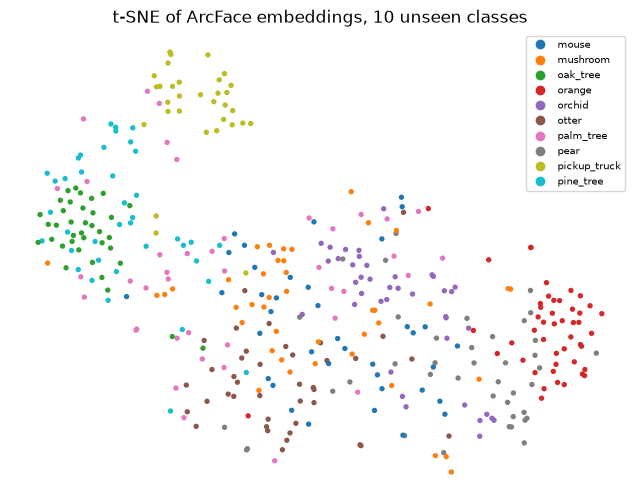

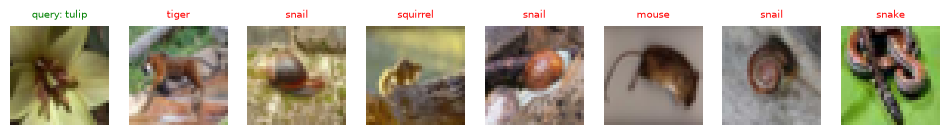

In [10]:
# Compute embeddings and run t-SNE for a subset of classes
z_vis = embed(trained["ArcFace"][0], test_x[:2000]).numpy()
y_vis = test_y[:2000].numpy()
pick = np.isin(y_vis, np.arange(10))
emb_2d = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(
    z_vis[pick]
)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=y_vis[pick], cmap="tab10", s=8)
plt.legend(scatter.legend_elements()[0], class_names[50:60], fontsize=7, loc="best")
plt.title("t-SNE of ArcFace embeddings, 10 unseen classes")
plt.axis("off")
plt.show()

# Display nearest neighbor images for a chosen query
query = 3
sims = torch.from_numpy(z_vis) @ torch.from_numpy(z_vis[query])
top = sims.argsort(descending=True)[:8]
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, i in zip(axes, top.tolist()):
    img = test_x[i] * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(
        class_names[50 + int(test_y[i])],
        fontsize=7,
        color="green" if test_y[i] == test_y[query] else "red",
    )
    ax.axis("off")
axes[0].set_title("query: " + class_names[50 + int(test_y[query])], fontsize=7)
plt.show()

# Summary

- **Mining and batch composition** matter more than the loss formula. Musgrave et al. ("A
  Metric Learning Reality Check", 2020) re-ran a decade of losses under equal conditions and
  found most gains vanished; tuned contrastive, triplet and proxy losses land within a few points.
- **Proxy losses** (ArcFace, CosFace, Proxy-Anchor) scale to millions of identities because each
  step compares against $C$ proxies instead of $O(B^2)$ pairs; face recognition uses ArcFace with
  $s = 64$, $m = 0.5$ on 512-D embeddings.
- **Verification thresholds.** Deployment picks a cosine threshold on a validation set to meet
  a false-accept rate (FAR $10^{-4}$–$10^{-6}$ for face unlock); Recall@K does not set it.
- **Today's default** is to start from a pretrained foundation encoder (DINOv2/v3, CLIP/SigLIP)
  and fine-tune with one of these losses or InfoNCE; from-scratch training like the run here is
  only for small, domain-specific data.
- **Serving.** Gallery embeddings go into an approximate nearest-neighbour index (HNSW, IVF-PQ in
  FAISS); normalised embeddings let inner-product search replace Euclidean search.

| Loss | Needs | Hardness handled by | Used in |
|---|---|---|---|
| Contrastive | pairs | margin on negatives only | Siamese verification, early re-ID |
| Triplet, batch-all | PK batches | every violating triplet in the batch | person re-ID, FaceNet-style training |
| Triplet, batch-hard | PK batches | hardest positive/negative per anchor | strong once warmed up; collapses from scratch |
| ArcFace | class labels | angular margin against all proxies | face recognition, product search |

- Retrieval quality is measured on **unseen classes**: training-class accuracy says nothing
  about the embedding.
- L2-normalised embeddings make distance, cosine and inner product interchangeable.
- Mining decides whether triplet training works: random triplets carry little signal and
  batch-hard from scratch collapses, while batch-all trains stably.